# Primera exploración de la base «SECOP II — Adiciones»

**Archivo que se analiza:** `SECOP_II_-_Adiciones_20260924.csv`

---

### Cómo usar este cuaderno

Ejecuta las celdas **en orden**, de arriba hacia abajo (`Shift + Enter`). Cada bloque tiene una explicación en lenguaje corriente y la celda de código que la ejecuta.

**Antes de empezar**, el archivo CSV tiene que estar en la misma carpeta que este cuaderno.

### Lo que vamos a responder

1. Qué es esta base, qué contiene y cómo es cada columna
2. Medidas de tendencia central y distribución de cada variable
3. Mapa de calor de correlaciones
4. Nulos, ceros, faltantes y duplicados: la basura que hay que botar
5. Gráfico de dispersión cruzando dos variables importantes
6. Columnas tipo llave para conectar esta tabla con otras

### El reto particular de esta base

Adelanto el problema, porque condiciona todo lo demás: **esta tabla no tiene ni una sola columna numérica**. Cuatro columnas son texto y una es fecha. Todo el análisis cuantitativo hay que fabricarlo, y la pieza central será **sacar los montos de dinero del texto libre**.

## Paso 0 · Preparar las herramientas

In [4]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Carga las librerías y fija el nombre del archivo y la fecha de corte.
# POR QUÉ    : re es la librería de expresiones regulares y se necesita más adelante para sacar los montos de dinero del texto.
# RESUELVE   : Deja el entorno listo para todo el cuaderno.
# ────────────────────────────────────────────────────────────────────

# !pip install pandas numpy matplotlib

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

%matplotlib inline
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ARCHIVO = "SECOP_II_-_Adiciones_20260924.csv"
CORTE   = pd.Timestamp("2026-09-24")
print("Librerías cargadas.")

Librerías cargadas.


In [5]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Define la paleta de colores y una función que limpia el marco de las gráficas.
# POR QUÉ    : Definir el estilo una sola vez evita repetirlo en cada figura.
# RESUELVE   : Unifica el aspecto visual de todas las gráficas.
# ────────────────────────────────────────────────────────────────────

# ── Colores y estilo de todas las figuras ────────────────────────
INK, INK2, GRID, HUE, ACC = "#2B2723", "#6B635A", "#E4E0D9", "#1F6F8B", "#B4581F"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "figure.dpi": 110,
})
CMAP = LinearSegmentedColormap.from_list(
    "div", ["#1F6F8B", "#8FB3C2", "#EDEAE4", "#D8A583", "#B4581F"])

def limpiar_ejes(ax, eje_y=True):
    """Quita el marco de arriba y de la derecha y pone una rejilla suave."""
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.grid(axis="y" if eje_y else "both", color=GRID, lw=.7)
    ax.set_axisbelow(True)
print("Estilo listo.")

Estilo listo.


## Paso 1 · Abrir el archivo y contar

Igual que antes, leemos todo como texto con `dtype=str` para que nada se convierta mal por su cuenta.

In [6]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Lee el archivo CSV y reporta su tamaño.
# POR QUÉ    : dtype=str obliga a leer todo como texto para que el programa no convierta mal ninguna columna por su cuenta. strip quita espacios sobrantes en los encabezados, que es un problema frecuente en archivos exportados.
# RESUELVE   : Trae los datos sin alterarlos.
# ────────────────────────────────────────────────────────────────────

df = pd.read_csv(ARCHIVO, dtype=str, keep_default_na=False, na_values=[""])
df.columns = [c.strip() for c in df.columns]

print(f"Filas    : {len(df):,}".replace(",", "."))
print(f"Columnas : {df.shape[1]}")
print(f"Memoria  : {df.memory_usage(deep=True).sum()/1e6:,.0f} MB".replace(",", "."))
print("\nNombres de las columnas tal como vienen:")
for col in df.columns:
    print("   ·", col)

Filas    : 28.633.868
Columnas : 5
Memoria  : 15.286 MB

Nombres de las columnas tal como vienen:
   · Identificador
   · ID_Contrato
   · Tipo
   · Descripcion
   · FechaRegistro


Le ponemos nombres cortos a las columnas para trabajar más cómodo, y miramos las primeras filas.

In [7]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Cambia los nombres de las columnas por versiones cortas.
# POR QUÉ    : Escribir df['Descripcion'] muchas veces es incómodo y se presta a errores de tildes. El diccionario contempla las dos formas en que puede venir el nombre.
# RESUELVE   : Hace el resto del código más corto y menos frágil.
# ────────────────────────────────────────────────────────────────────

REN = {"Identificador": "identificador", "ID_Contrato": "id_contrato",
       "Tipo": "tipo", "Descripcion": "descripcion", "Descripción": "descripcion",
       "FechaRegistro": "fecha"}
df = df.rename(columns={k: v for k, v in REN.items() if k in df.columns})
df.head(3)

,identificador,id_contrato,tipo,descripcion,fecha
0,CO1.CTRMOD.499720,CO1.PCCNTR.285227,MODIFICACION GENERAL,ADICIONAR EL VALOR DEL CONTRATO DE PRESTACIoN ...,09/01/2018
1,CO1.CTRMOD.19129696,CO1.PCCNTR.6794799,CONCLUSION,DANDO CUMPLIMIENTO A LOS LINEAMIENTOS EN LAS C...,05/02/2025
2,CO1.CTRMOD.5570045,CO1.PCCNTR.2134579,MODIFICACION GENERAL,CONSIDERANDO: 1) QUE LA SUBRED INTEGRADA DE SE...,02/01/2021


## Paso 2 · Qué representa una fila

Misma pregunta que en la otra base: comparamos filas contra contratos distintos.

In [8]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Compara cuántas filas hay contra cuántos contratos distintos.
# POR QUÉ    : Si hay menos contratos que filas, un mismo contrato aparece varias veces.
# RESUELVE   : Responde qué representa una fila, que condiciona todo lo demás.
# ────────────────────────────────────────────────────────────────────

print(f"Filas totales         : {len(df):,}".replace(",", "."))
print(f"Contratos distintos   : {df['id_contrato'].nunique():,}".replace(",", "."))
print(f"Modificaciones por contrato (promedio): {len(df)/df['id_contrato'].nunique():.2f}")

Filas totales         : 28.633.868
Contratos distintos   : 3.907.005
Modificaciones por contrato (promedio): 7.33


**Conclusión:**

> **Una fila = una modificación hecha a un contrato.**

Un mismo contrato aparece varias veces, una por cada vez que lo modificaron. Igual que en la base de grupos, es una **tabla en formato largo**: el «padre» es el contrato y los «hijos» son sus modificaciones.

**Ojo:** contar filas no es contar contratos.

## Punto 1 · Descripción de las variables

### 1.1 Qué es esta base y para qué sirve

- **Nombre oficial:** SECOP II — Adiciones
- **Identificador:** `cb9c-h8sn` · https://www.datos.gov.co/d/cb9c-h8sn
- **Quién la publica:** Agencia Nacional de Contratación Pública — Colombia Compra Eficiente
- **Cada cuánto se actualiza:** diaria
- **Descripción oficial:** *«Adiciones hechas a los contratos firmados en la plataforma SECOP II»*

**El propósito de fondo.** Cuando el Estado firma un contrato, el precio y el plazo quedan fijados. Pero casi nunca se quedan quietos: se adicionan recursos, se prorroga el plazo, se suspende la ejecución, se liquida antes de tiempo. Cada uno de esos movimientos queda registrado aquí.

Esta base es **la memoria de cómo cambian los contratos públicos después de firmados**. Eso la vuelve valiosa para tres preguntas concretas:

1. **¿Los contratos se firman subdimensionados a propósito?** Si un contrato se adiciona a los quince días de firmado, algo falló en la planeación, o el valor inicial se puso bajo para evitar una licitación más exigente.
2. **¿Qué entidades modifican más?** Una entidad que modifica casi todos sus contratos tiene un problema de planeación, no de mala suerte.
3. **¿Cuánto crece realmente el gasto público después de la firma?** El valor adjudicado es una cosa y el valor final es otra.

### 1.2 Las columnas, una por una

In [9]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Arma la tabla-diccionario de las 5 columnas.
# POR QUÉ    : Se combina la información oficial del catálogo con el conteo real de valores llenos, distintos y un ejemplo tomado del archivo.
# RESUELVE   : Entrega el punto 1 del ejercicio.
# ────────────────────────────────────────────────────────────────────

API = {
 "identificador":"identificador|texto|Identificador único de la modificación",
 "id_contrato":"id_contrato|texto|Identificador del contrato modificado",
 "tipo":"tipo|texto|Tipo de modificación según su impacto",
 "descripcion":"descripcion|texto|Justificación escrita a mano por el funcionario",
 "fecha":"fecharegistro|fecha|Cuándo se registró la modificación",
}

filas = []
for i, col in enumerate(df.columns, 1):
    campo, tipo, desc = API.get(col, "?|?|?").split("|")
    filas.append({"#": i, "Columna": col, "Campo API": campo, "Tipo": tipo,
                  "Qué guarda": desc,
                  "Llenos": df[col].notna().sum(),
                  "Únicos": df[col].nunique(dropna=True),
                  "Ejemplo": str(df[col].dropna().iloc[0])[:60] if df[col].notna().any() else ""})

pd.DataFrame(filas)

,#,Columna,Campo API,Tipo,Qué guarda,Llenos,Únicos,Ejemplo
0,1,identificador,identificador,texto,Identificador único de la modificación,28633868,8272724,CO1.CTRMOD.499720
1,2,id_contrato,id_contrato,texto,Identificador del contrato modificado,28633868,3907005,CO1.PCCNTR.285227
2,3,tipo,tipo,texto,Tipo de modificación según su impacto,28633868,10,MODIFICACION GENERAL
3,4,descripcion,descripcion,texto,Justificación escrita a mano por el funcionario,28633868,3429990,ADICIONAR EL VALOR DEL CONTRATO DE PRESTACIoN ...
4,5,fecha,fecharegistro,fecha,Cuándo se registró la modificación,28633868,843,09/01/2018


Y los tipos de modificación que existen:

In [10]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Lista los tipos de modificación y cuántas veces aparece cada uno.
# POR QUÉ    : Es la única columna de categorías de la tabla, así que conviene conocerla antes de usarla para agrupar.
# RESUELVE   : Muestra de qué está hecha la variable que después se usa en el diagrama de cajas.
# ────────────────────────────────────────────────────────────────────

df["tipo"].value_counts(dropna=False).head(15)

tipo
MODIFICACION GENERAL     13623529
CONCLUSION                7072488
No definido               6078023
ADICION EN EL VALOR        566809
CESION                     481530
REACTIVACIoN               435449
SUSPENSIoN                 375503
EXTENSION                     391
REDUCCION EN EL VALOR         145
EXPIRACION                      1
Name: count, dtype: int64

### 1.3 El problema grande de esta base

Mira la columna **Tipo** de la tabla de arriba:

> **Ni una sola columna es numérica.** Cuatro son texto y una es fecha.

En la base de grupos al menos existía una columna de números de la cual agarrarse. Aquí no hay ninguna. El ejercicio pide medidas de tendencia central, correlaciones y un gráfico de dispersión, y las tres cosas necesitan números.

**Todo el análisis cuantitativo hay que fabricarlo.** Eso es lo que hacemos en el paso siguiente.

## Paso 3 · Limpieza y construcción de variables

### 3.1 Los vacíos disfrazados

Igual que en la otra base, aparecen textos que *significan* vacío: `"No Definido"`, `"No Provisto"`. Para el computador son texto válido. Hay que traducirlos.

In [11]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Traduce a vacío los textos que significan vacío.
# POR QUÉ    : Igual que en la otra base, aparecen 'No Definido' y 'No Provisto' como texto. El programa los lee como dato válido.
# RESUELVE   : Sin este paso, el conteo de datos faltantes da mal.
# ────────────────────────────────────────────────────────────────────

CENTINELAS = {"No Definido", "No definido", "NO DEFINIDO", "No Provisto",
              "No provisto", "NO PROVISTO", "No Aplica", "N/A", "NA",
              "SIN DATO", "-", "."}

antes = df.notna().sum().sum()
for col in df.columns:
    df[col] = df[col].where(~df[col].isin(CENTINELAS), np.nan)

print(f"Celdas que parecían llenas y en realidad estaban vacías: "
      f"{antes - df.notna().sum().sum():,}".replace(",", "."))

Celdas que parecían llenas y en realidad estaban vacías: 6.098.786


### 3.2 Las fechas

In [12]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Convierte la columna de fecha a fecha de verdad.
# POR QUÉ    : format='mixed' permite que pandas reconozca varios formatos distintos dentro de la misma columna, que es común en datos cargados a mano.
# RESUELVE   : Habilita las restas entre fechas.
# ────────────────────────────────────────────────────────────────────

df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce", format="mixed")

print(f"Fechas leídas : {df['fecha'].notna().sum():,}".replace(",", "."))
print(f"Rango         : {df['fecha'].min().date()}  ->  {df['fecha'].max().date()}")

Fechas leídas : 28.633.868
Rango         : 2015-01-01  ->  2026-09-09


### 3.3 La jugada central: sacar la plata del texto

Esta es la parte más interesante del ejercicio y hay que explicarla bien, porque un evaluador la va a cuestionar.

La descripción es texto libre. Un funcionario escribe cosas como:

> *«Ampliación de recursos por $15.693.000 y extensión de tres meses en contrato de servicios profesionales 066/2018»*

Ahí hay un número que vale oro: **15.693.000 pesos**. Lo vamos a encontrar con una **expresión regular**, que es una forma de decirle al computador «búscame algo que se parezca a esto»: un signo de pesos seguido de dígitos con puntos o comas.

Después hay que normalizarlo, porque en Colombia el punto separa los miles y la coma los decimales, al revés de como lo entiende el computador por defecto.

**Cuatro advertencias que debes escribir en tu informe:**

1. **Es una estimación, no un dato oficial.** La plataforma no publica el valor de la adición en una columna aparte.
2. **Cuando el texto menciona varias cifras, tomamos la mayor.** Si dice «se adiciona en $19.000.000 para un total de $57.000.000», toma los 57 millones. Es una decisión discutible y hay que declararla.
3. **Se descartan cifras por fuera de un rango razonable** (menores a mil pesos o mayores a diez billones), porque suelen ser números de resolución, fechas o artículos de ley.
4. **Muchas descripciones no traen ninguna cifra.** Esas filas quedan fuera del análisis de valor, sin que eso signifique que sean basura.

In [13]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Define cómo sacar los montos de dinero del texto libre.
# POR QUÉ    : La base no tiene columna de valor: la plata está escrita dentro de la justificación. PATRON busca algo que se parezca a una cifra de dinero. a_numero arregla el problema de que en Colombia el punto separa miles y la coma decimales, al revés de como lo entiende el computador. extraer_valor toma la cifra MÁS GRANDE cuando hay varias, y descarta las que están fuera de un rango razonable, porque suelen ser números de resolución o de artículo.
# RESUELVE   : Construye la única variable de dinero de todo el análisis. Es una estimación, no un dato oficial, y eso hay que declararlo.
# ────────────────────────────────────────────────────────────────────

PATRON = re.compile(r"\$\s*([\d][\d\.,]{3,})|([\d]{1,3}(?:[\.,]\d{3}){1,4})")

def a_numero(txt):
    """Convierte '15.693.000' o '15,693,000.50' a un número de verdad."""
    t = txt.strip().rstrip(".,")
    if "." in t and "," in t:
        t = (t.replace(".", "").replace(",", ".")
             if t.rfind(",") > t.rfind(".") else t.replace(",", ""))
    elif "," in t:
        t = t.replace(",", "") if len(t.split(",")[-1]) == 3 else t.replace(",", ".")
    elif "." in t:
        t = t.replace(".", "") if len(t.split(".")[-1]) == 3 else t
    try:
        return float(t)
    except ValueError:
        return np.nan

def extraer_valor(texto):
    """Devuelve el monto MÁS GRANDE mencionado en la descripción."""
    if not isinstance(texto, str):
        return np.nan
    candidatos = []
    for m in PATRON.finditer(texto):
        v = a_numero(m.group(1) or m.group(2))
        if np.isfinite(v) and 1_000 <= v <= 1e13:
            candidatos.append(v)
    return max(candidatos) if candidatos else np.nan

# prueba rápida antes de aplicarlo a todo
for ejemplo in ["Adición por $15.693.000 y tres meses más",
                "Se adiciona en la suma de $ 1.968.000 m/cte",
                "Cierre de expediente contractual",
                "Ajuste según Resolución NO. 0053 DEL 27 DE ENERO DE 2021 por $4.500.000"]:
    print(f"{extraer_valor(ejemplo)!s:>18}  <-  {ejemplo[:60]}")

        15693000.0  <-  Adición por $15.693.000 y tres meses más
         1968000.0  <-  Se adiciona en la suma de $ 1.968.000 m/cte
               nan  <-  Cierre de expediente contractual
         4500000.0  <-  Ajuste según Resolución NO. 0053 DEL 27 DE ENERO DE 2021 por


La prueba funciona. Ahora lo aplicamos a toda la tabla. Esta celda puede tardar un par de minutos.

In [14]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Aplica la extracción a toda la tabla y mide qué tanto funcionó.
# POR QUÉ    : map recorre fila por fila. El porcentaje de éxito importa porque define sobre cuántos casos se puede hablar de plata.
# RESUELVE   : Crea la columna valor_detectado y cuantifica su cobertura.
# ────────────────────────────────────────────────────────────────────

df["valor_detectado"] = df["descripcion"].map(extraer_valor)

detectados = df["valor_detectado"].notna().sum()
print(f"Descripciones con monto detectado : {detectados:,}".replace(",", "."))
print(f"Descripciones sin monto           : {len(df)-detectados:,}".replace(",", "."))
print(f"Porcentaje con monto              : {100*detectados/len(df):.1f} %")

Descripciones con monto detectado : 1.838.656
Descripciones sin monto           : 26.795.212
Porcentaje con monto              : 6.4 %


### 3.4 Las demás variables numéricas

| Variable | Cómo se construye | Qué mide |
|---|---|---|
| `valor_detectado` | El monto sacado del texto | Cuánta plata mueve la modificación |
| `largo_descripcion` | Cuántos caracteres tiene el texto | Qué tan detallada es la justificación |
| `palabras_descripcion` | Cuántas palabras tiene | Lo mismo, en otra unidad |
| `n_modificaciones` | Cuántas veces aparece ese contrato | Qué tan inestable fue el contrato |
| `orden_modificacion` | Si es la 1.ª, 2.ª, 3.ª del contrato | Posición en la secuencia |
| `dias_desde_primera` | Días entre esta y la primera del contrato | Qué tan tarde llega el cambio |
| `dias_entre_modificaciones` | Días desde la modificación anterior | Con qué ritmo se modifica |
| `antiguedad_dias` | Días entre la modificación y hoy | Qué tan vieja es |

In [15]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Construye las demás variables numéricas derivadas.
# POR QUÉ    : sort_values ordena por contrato y fecha, lo cual es indispensable: sin ese orden, 'la primera modificación' y 'la anterior' quedarían mal calculadas. cumcount numera las modificaciones dentro de cada contrato y diff mide los días transcurridos desde la anterior.
# RESUELVE   : Completa la materia prima de los puntos 2, 3 y 5.
# ────────────────────────────────────────────────────────────────────

df["largo_descripcion"]    = df["descripcion"].fillna("").str.len()
df["palabras_descripcion"] = df["descripcion"].fillna("").str.split().str.len()

df = df.sort_values(["id_contrato", "fecha"], kind="stable")
g = df.groupby("id_contrato", dropna=False)
df["n_modificaciones"]          = g["identificador"].transform("size")
df["orden_modificacion"]        = g.cumcount() + 1
df["dias_desde_primera"]        = (df["fecha"] - g["fecha"].transform("min")).dt.days
df["dias_entre_modificaciones"] = g["fecha"].diff().dt.days
df["antiguedad_dias"]           = (CORTE - df["fecha"]).dt.days

NUM = ["valor_detectado", "largo_descripcion", "palabras_descripcion",
       "n_modificaciones", "orden_modificacion", "dias_desde_primera",
       "dias_entre_modificaciones", "antiguedad_dias"]
ETQ = {"valor_detectado":"Valor detectado ($)", "largo_descripcion":"Largo del texto",
       "palabras_descripcion":"Palabras del texto",
       "n_modificaciones":"Modificaciones del contrato",
       "orden_modificacion":"Número de modificación",
       "dias_desde_primera":"Días desde la primera",
       "dias_entre_modificaciones":"Días desde la anterior",
       "antiguedad_dias":"Antigüedad (días)"}

print("Variables numéricas construidas:")
for v in NUM:
    print("   ·", v)

Variables numéricas construidas:
   · valor_detectado
   · largo_descripcion
   · palabras_descripcion
   · n_modificaciones
   · orden_modificacion
   · dias_desde_primera
   · dias_entre_modificaciones
   · antiguedad_dias


## Punto 2 · Medidas de tendencia central y distribución

Recordatorio rápido:

- **Media:** sumar todo y dividir. Se desvía con los valores extremos.
- **Mediana:** el valor del medio al ordenar. Los extremos no la mueven.
- **Moda:** el valor que más se repite.
- **Desviación estándar:** qué tan regados están los datos.
- **Asimetría:** si la distribución está corrida hacia un lado.

In [16]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Calcula media, mediana, moda, desviación, percentiles y asimetría.
# POR QUÉ    : cv es el coeficiente de variación: la desviación dividida por la media. Sirve para comparar la dispersión de variables que están en unidades distintas.
# RESUELVE   : Entrega el punto 2 del ejercicio.
# ────────────────────────────────────────────────────────────────────

tabla = df[NUM].describe(percentiles=[.05, .25, .5, .75, .95]).T
tabla["mediana"]   = df[NUM].median()
tabla["moda"]      = [df[c].mode().iloc[0] if not df[c].mode().empty else np.nan for c in NUM]
tabla["asimetria"] = df[NUM].skew()
tabla["cv"]        = tabla["std"] / tabla["mean"]
tabla.round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max,mediana,moda,asimetria,cv
valor_detectado,1838656.0,6.480350e+08,1.979686e+10,1000.0,124877.5,4033333.0,17128000.0,59832052.75,1.102359e+09,9.166500e+12,17128000.0,162010.0,194.37,30.55
largo_descripcion,28633868.0,1.810800e+02,2.628100e+02,0.0,14.0,18.0,69.0,208.00,8.780000e+02,1.200000e+03,69.0,15.0,2.19,1.45
palabras_descripcion,28633868.0,2.857000e+01,4.154000e+01,0.0,2.0,3.0,11.0,33.00,1.400000e+02,3.010000e+02,11.0,2.0,2.18,1.45
n_modificaciones,28633868.0,2.411000e+01,4.084000e+01,1.0,2.0,6.0,14.0,29.00,7.900000e+01,2.078000e+03,14.0,4.0,21.15,1.69
orden_modificacion,28633868.0,1.255000e+01,2.458000e+01,1.0,1.0,3.0,6.0,14.00,4.500000e+01,2.078000e+03,6.0,1.0,24.93,1.96
dias_desde_primera,28633868.0,1.818200e+02,3.501100e+02,0.0,0.0,0.0,0.0,242.00,8.530000e+02,3.774000e+03,0.0,0.0,3.15,1.93
dias_entre_modificaciones,24726863.0,3.357000e+01,1.540400e+02,0.0,0.0,0.0,0.0,0.00,2.110000e+02,3.774000e+03,0.0,0.0,7.60,4.59
antiguedad_dias,28633868.0,6.119000e+02,6.478800e+02,15.0,50.0,115.0,234.0,997.00,1.904000e+03,4.284000e+03,234.0,145.0,1.34,1.06


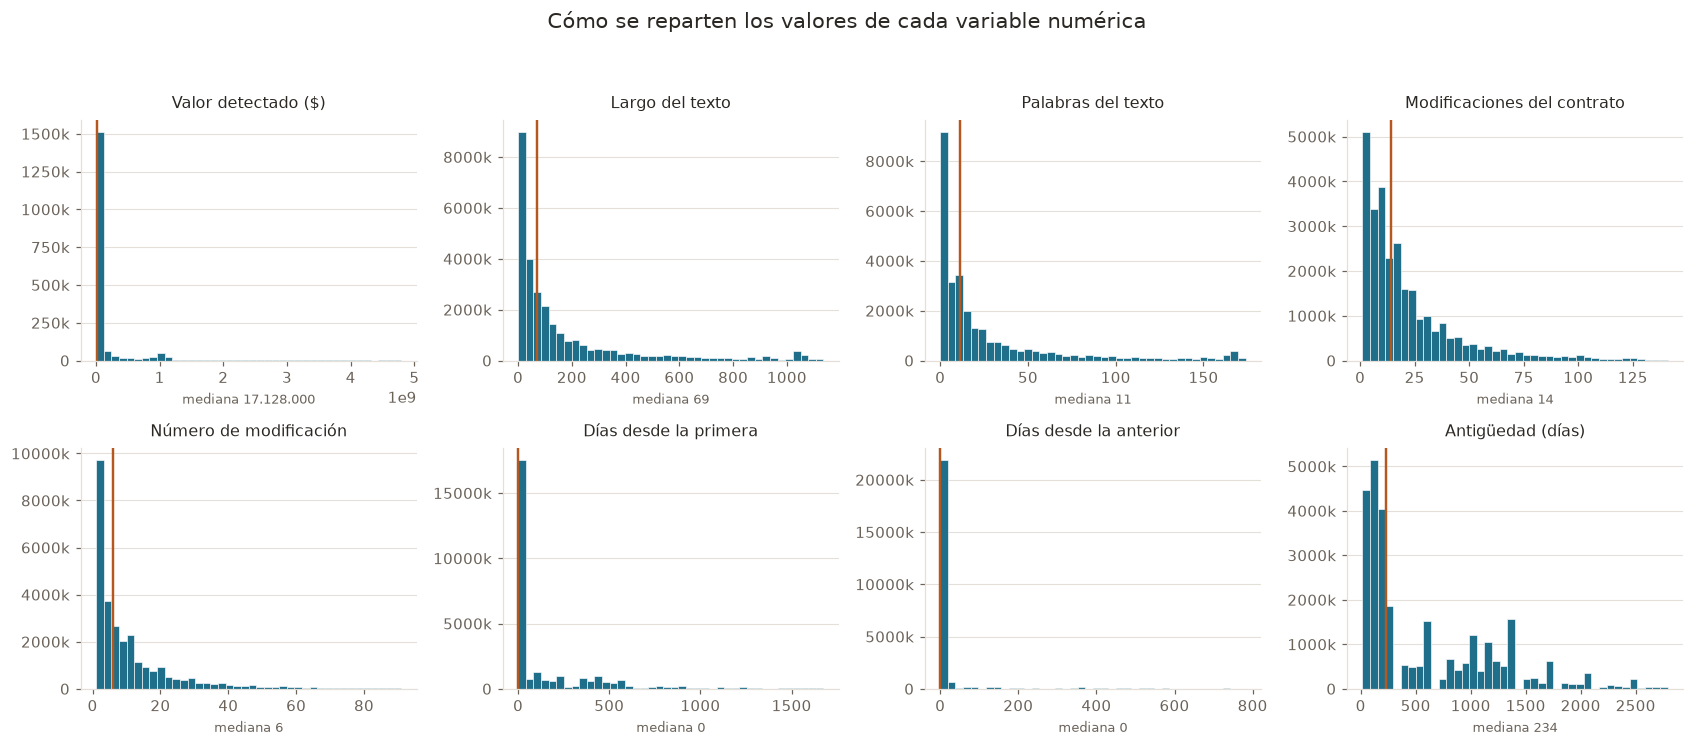

In [17]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Dibuja un histograma por cada variable numérica.
# POR QUÉ    : Todas las variables se recortan en el percentil 99, porque varias tienen colas muy largas y un solo valor extremo aplastaría la gráfica.
# RESUELVE   : Muestra la forma de cada distribución.
# ────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 4, figsize=(15.5, 6.8))
for ax, col in zip(axes.ravel(), NUM):
    s = df[col].dropna()
    s = s[s <= s.quantile(.99)]
    if len(s) == 0:
        ax.axis("off"); continue
    ax.hist(s, bins=40, color=HUE, edgecolor="white", linewidth=.4)
    ax.axvline(df[col].median(), color=ACC, lw=1.6)
    ax.set_title(ETQ[col], fontsize=10.5, color=INK, pad=8)
    ax.set_xlabel(f"mediana {df[col].median():,.0f}".replace(",", "."), fontsize=8.5)
    ax.yaxis.set_major_formatter(lambda v, p: f"{v/1000:.0f}k" if v >= 1000 else f"{v:.0f}")
    limpiar_ejes(ax)
fig.suptitle("Cómo se reparten los valores de cada variable numérica",
             fontsize=13.5, color=INK, y=.99)
fig.tight_layout(rect=[0, 0, 1, .95])
plt.show()

### Qué mirar en el resultado

| Señal | Qué significa |
|---|---|
| La media del valor es mucho mayor que la mediana | Hay unas pocas adiciones gigantes jalando el promedio. Para describir el caso típico usa la mediana |
| `n_modificaciones` con mediana 1 o 2 | La mayoría de contratos se modifican poco y un puñado se modifica muchísimo |
| `largo_descripcion` con una moda muy marcada | Hay textos de plantilla que se copian y pegan |
| `dias_desde_primera` con mediana baja | Las modificaciones se concentran al comienzo, lo que apunta a problemas de planeación |

## Punto 3 · Mapa de calor de correlaciones

Recordatorio: la correlación va de −1 a 1. Cerca de 1 las dos suben juntas, cerca de −1 una sube y la otra baja, cerca de 0 no tienen relación. Y la frase de cajón: **correlación no es causa**.

findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


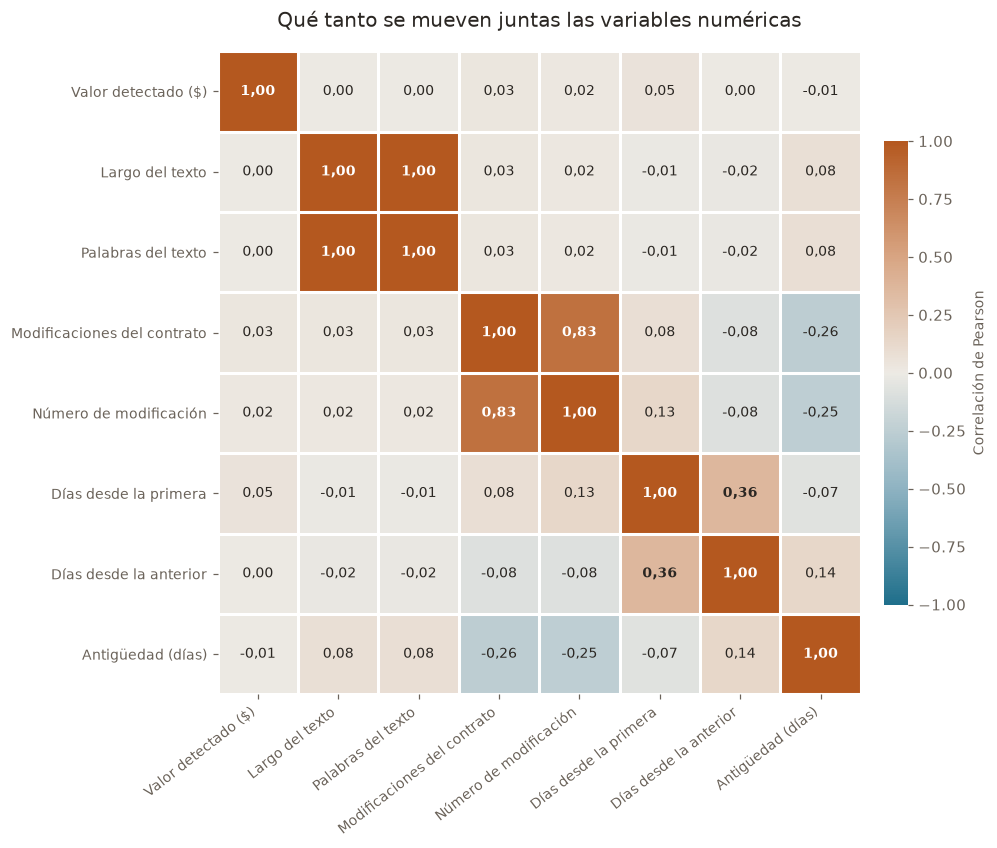


Correlación de Spearman:


,valor_detectado,largo_descripcion,palabras_descripcion,n_modificaciones,orden_modificacion,dias_desde_primera,dias_entre_modificaciones,antiguedad_dias
valor_detectado,1.000,0.319,0.317,0.315,0.242,0.214,0.010,-0.159
largo_descripcion,0.319,1.000,0.993,-0.060,-0.018,-0.030,-0.023,0.091
palabras_descripcion,0.317,0.993,1.000,-0.048,-0.010,-0.026,-0.019,0.094
n_modificaciones,0.315,-0.060,-0.048,1.000,0.778,0.229,-0.210,-0.578
orden_modificacion,0.242,-0.018,-0.010,0.778,1.000,0.423,-0.202,-0.548
dias_desde_primera,0.214,-0.030,-0.026,0.229,0.423,1.000,0.334,-0.022
dias_entre_modificaciones,0.010,-0.023,-0.019,-0.210,-0.202,0.334,1.000,0.348
antiguedad_dias,-0.159,0.091,0.094,-0.578,-0.548,-0.022,0.348,1.000


In [18]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Calcula las correlaciones y las pinta como mapa de calor.
# POR QUÉ    : Se calculan las dos versiones: Pearson mide relaciones en línea recta y Spearman detecta las que suben o bajan sin ser rectas.
# RESUELVE   : Entrega el punto 3 del ejercicio.
# ────────────────────────────────────────────────────────────────────

corr = df[NUM].corr()

fig, ax = plt.subplots(figsize=(9.2, 7.6))
im = ax.imshow(corr.values, cmap=CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM))); ax.set_yticks(range(len(NUM)))
ax.set_xticklabels([ETQ[c] for c in NUM], rotation=38, ha="right", fontsize=9)
ax.set_yticklabels([ETQ[c] for c in NUM], fontsize=9)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center",
                fontsize=9, color="white" if abs(v) > .55 else INK,
                fontweight="600" if abs(v) > .3 else "normal")
ax.set_xticks(np.arange(-.5, len(NUM), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(NUM), 1), minor=True)
ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=.72, pad=.03)
cb.set_label("Correlación de Pearson", fontsize=9, color=INK2); cb.outline.set_visible(False)
ax.set_title("Qué tanto se mueven juntas las variables numéricas",
             fontsize=13, color=INK, pad=16)
plt.show()

print("\nCorrelación de Spearman:")
df[NUM].corr(method="spearman").round(3)

### Qué relaciones vale la pena buscar

| Par de variables | Qué querría decir si sale fuerte |
|---|---|
| `orden_modificacion` ↔ `valor_detectado` | Las modificaciones posteriores mueven más o menos plata que las primeras |
| `n_modificaciones` ↔ `valor_detectado` | Los contratos que más se modifican son los de mayor valor |
| `largo_descripcion` ↔ `valor_detectado` | Entre más plata, más se explica. Sería señal de que hay autocontrol |
| `dias_desde_primera` ↔ `valor_detectado` | Las modificaciones tardías son más costosas |

**Trampa que hay que declarar:** `orden_modificacion`, `dias_desde_primera` y `dias_entre_modificaciones` se calculan todas a partir de la misma fecha. Si salen correlacionadas entre sí, en buena parte es **por construcción**, no por un fenómeno real. Eso se llama **correlación espuria** y mencionarlo suma puntos.

## Punto 4 · Nulos, ceros, faltantes y duplicados

### 4.1 Cuánto falta en cada columna

In [19]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Cuenta cuántos datos faltan en cada columna.
# POR QUÉ    : Se corre después de traducir los centinelas, así que el conteo ya es real.
# RESUELVE   : Primera parte del punto 4.
# ────────────────────────────────────────────────────────────────────

cols = ["identificador", "id_contrato", "tipo", "descripcion", "fecha"]
pd.DataFrame({"vacíos": df[cols].isna().sum(),
              "% vacío": (df[cols].isna().mean()*100).round(2)})

,vacíos,% vacío
identificador,0,0.00
id_contrato,0,0.00
tipo,6078023,21.23
descripcion,20763,0.07
fecha,0,0.00


### 4.2 Duplicados

In [20]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Busca filas e identificadores duplicados.
# POR QUÉ    : El identificador debería ser único: una modificación, un registro. Si se repite, hubo cargue doble.
# RESUELVE   : Detecta errores de carga.
# ────────────────────────────────────────────────────────────────────

print(f"Filas idénticas de principio a fin : {df.duplicated().sum():,}".replace(",", "."))
print(f"Identificadores repetidos          : {df['identificador'].duplicated().sum():,}".replace(",", "."))
print("   (el identificador debería ser único: una modificación, un registro)")

Filas idénticas de principio a fin : 0
Identificadores repetidos          : 20.361.144
   (el identificador debería ser único: una modificación, un registro)


### 4.3 La trampa propia de esta base: las descripciones de plantilla

Esta es la novedad respecto de la otra base. Muchos funcionarios copian y pegan el mismo texto. Si una sola frase aparece miles de veces, esa columna sirve mucho menos de lo que parece, porque no está describiendo nada en particular.

In [21]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Mide el problema de las descripciones de plantilla.
# POR QUÉ    : duplicated(keep=False) marca todas las apariciones de un texto repetido, no solo las copias. Si una frase aparece miles de veces, esa columna describe mucho menos de lo que parece.
# RESUELVE   : Revela una limitación propia de esta base que no se ve a simple vista.
# ────────────────────────────────────────────────────────────────────

print(f"Descripciones que se repiten          : "
      f"{df['descripcion'].duplicated(keep=False).sum():,}".replace(",", "."))
print(f"Descripciones vacías o de una palabra : "
      f"{(df['palabras_descripcion'] <= 1).sum():,}".replace(",", "."))
print("\nLas 10 descripciones más repetidas:")
top = df["descripcion"].value_counts().head(10)
for texto, veces in top.items():
    print(f"   {veces:>7,}  |  {str(texto)[:80]}".replace(",", "."))

Descripciones que se repiten          : 27.135.148
Descripciones vacías o de una palabra : 1.146.038

Las 10 descripciones más repetidas:
   4.906.284  |  Sin Descripción
   516.757  |  MODIFICACION
   333.279  |  ADICION Y PRORROGA
   291.361  |  MODIFICACIoN
   222.111  |  ADICIoN Y PRORROGA
   165.842  |  SE REALIZA MODIFICACIoN DE CONFORMIDAD CON EL REQUERIMIENTO REALIZADO POR EL SUP
   100.871  |  CONSIDERANDO: 1) QUE LA SUBRED INTEGRADA DE SERVICIOS DE SALUD SUR OCCIDENTE ESE
    76.479  |  CONSIDERANDO: 1) QUE LA SUBRED INTEGRADA DE SERVICIOS DE SALUD SUR OCCIDENTE ESE
    62.228  |  ACTA DE LIQUIDACION
    59.109  |  TERMINACION DE CONTRATO


### 4.4 Valores imposibles

In [22]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Busca fechas y valores imposibles.
# POR QUÉ    : SECOP II no existía antes de 2013 y ninguna fecha puede estar en el futuro. Las filas sin monto detectable se cuentan aparte porque no son basura.
# RESUELVE   : Separa el error real del dato legítimamente ausente.
# ────────────────────────────────────────────────────────────────────

print("VALORES IMPOSIBLES O SOSPECHOSOS\n" + "-" * 60)
print(f"Fechas anteriores a 2013 (SECOP II no existía) : {(df['fecha'] < '2013-01-01').sum():,}".replace(",", "."))
print(f"Fechas en el futuro                            : {(df['fecha'] > CORTE).sum():,}".replace(",", "."))
print(f"Filas sin monto detectable                     : {df['valor_detectado'].isna().sum():,}".replace(",", "."))
print("   (estas NO son basura: son filas donde no se escribió una cifra)")

VALORES IMPOSIBLES O SOSPECHOSOS
------------------------------------------------------------
Fechas anteriores a 2013 (SECOP II no existía) : 0
Fechas en el futuro                            : 0
Filas sin monto detectable                     : 26.795.212
   (estas NO son basura: son filas donde no se escribió una cifra)


### 4.5 Cuánto hay que botar

In [23]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Junta los problemas y mide cuánto habría que botar.
# POR QUÉ    : El símbolo | significa 'o': basta con tener uno de los problemas para descartar la fila.
# RESUELVE   : Cierra el punto 4 con una conclusión cuantificada.
# ────────────────────────────────────────────────────────────────────

descartar = (df["identificador"].isna() | df["id_contrato"].isna()
             | df["fecha"].isna() | df.duplicated())

print(f"Filas a descartar : {descartar.sum():,}".replace(",", "."))
print(f"Porcentaje        : {100*descartar.mean():.2f} %")
print(f"Filas que quedan  : {(~descartar).sum():,}".replace(",", "."))

Filas a descartar : 0
Porcentaje        : 0.00 %
Filas que quedan  : 28.633.868


**Cómo interpretarlo:** si se va menos del 5 %, la base está sana. Si se va más del 20 %, hay que explicar muy bien qué quedó afuera y por qué.

## Punto 5 · Gráfico de dispersión

### 5.1 Qué variables y por qué

> Un gráfico de dispersión necesita que **las dos variables sean continuas**.

Si cruzáramos `orden_modificacion` —que solo puede ser 1, 2, 3…— los puntos se apilarían en columnas verticales y el resultado parecería un código de barras. Para esa clase de variable la herramienta correcta es un diagrama de cajas, que hacemos después.

Cruzamos entonces:

- **Eje horizontal:** días transcurridos desde la primera modificación del contrato.
- **Eje vertical:** valor detectado en el texto.

**La pregunta que responde:** ¿las modificaciones tardías mueven más plata?

### 5.2 El problema de la escala

El valor de las adiciones va desde unos pocos miles de pesos hasta miles de millones. En escala normal el eje tiene que estirarse tanto que la mayoría de los casos queda aplastada contra el piso. Por eso dibujamos **dos paneles, los dos en escala normal**: uno con el rango completo y otro recortado en el percentil 95.

In [24]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Prepara los datos del scatter y mide la correlación.
# POR QUÉ    : Se recorta en 1.500 días porque más allá los casos son muy pocos y estiran el eje sin aportar. Las dos correlaciones se imprimen antes de dibujar, para saber qué esperar de la gráfica.
# RESUELVE   : Prepara el punto 5 y anticipa su lectura.
# ────────────────────────────────────────────────────────────────────

sc = df.dropna(subset=["dias_desde_primera", "valor_detectado"]).copy()
sc = sc[sc["dias_desde_primera"] <= 1500]

print(f"Puntos disponibles   : {len(sc):,}".replace(",", "."))
print(f"Correlación Pearson  : {sc['dias_desde_primera'].corr(sc['valor_detectado']):.3f}")
print(f"Correlación Spearman : "
      f"{sc['dias_desde_primera'].corr(sc['valor_detectado'], method='spearman'):.3f}")

Puntos disponibles   : 1.831.840
Correlación Pearson  : 0.033
Correlación Spearman : 0.217


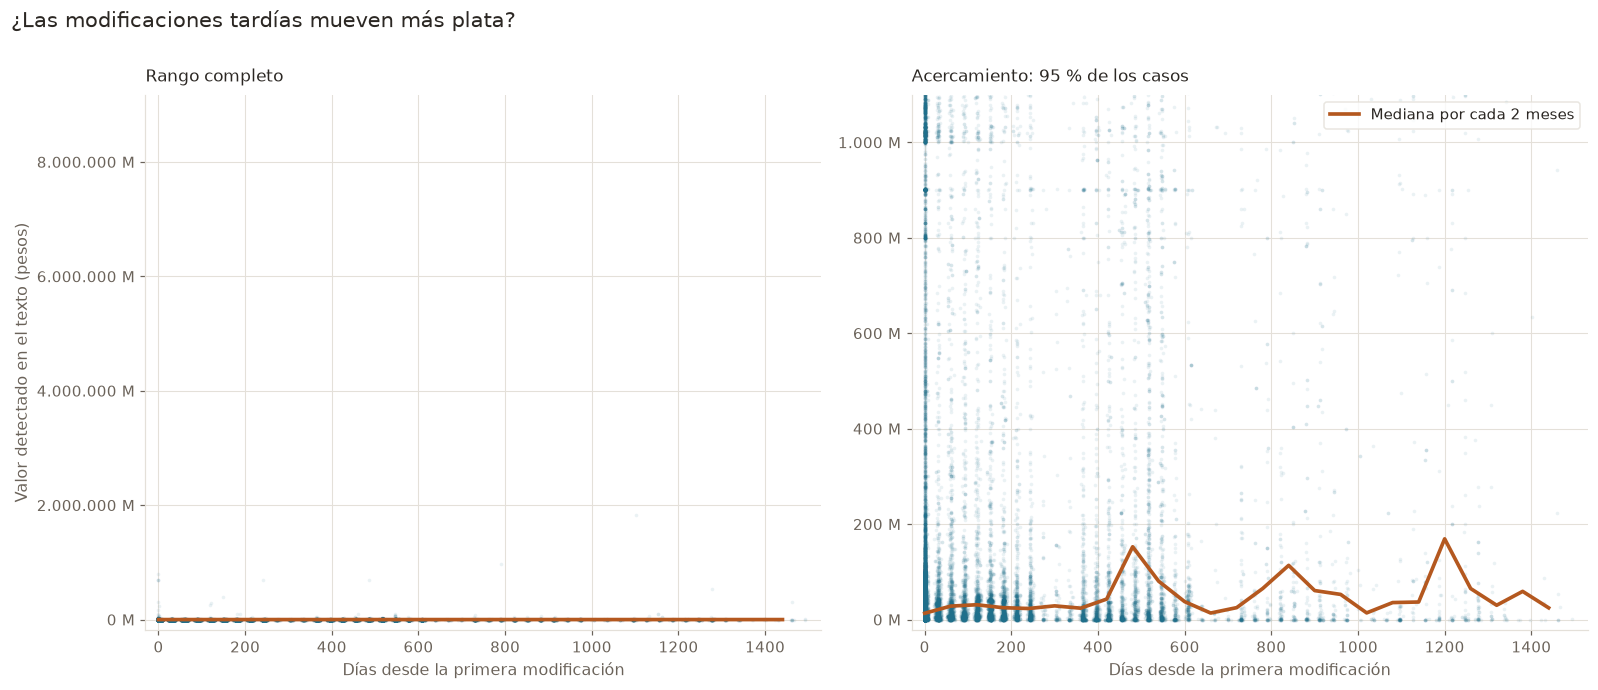

In [25]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Dibuja el gráfico de dispersión en dos paneles.
# POR QUÉ    : Se toma una muestra porque dibujar cientos de miles de puntos es lento y produce una mancha. Los dos paneles usan escala normal: uno con el rango completo y otro recortado en el percentil 95, porque los valores van de miles a miles de millones.
# RESUELVE   : Entrega el punto 5 del ejercicio.
# ────────────────────────────────────────────────────────────────────

m = sc.sample(min(40000, len(sc)), random_state=7)
tope = sc["valor_detectado"].quantile(.95)
sc["tramo"] = (sc["dias_desde_primera"] // 60) * 60
tr = sc.groupby("tramo")["valor_detectado"].agg(["median", "count"])
tr = tr[tr["count"] >= 30]

fig, axes = plt.subplots(1, 2, figsize=(14.6, 6.2))
for ax, lim, tit in [(axes[0], sc["valor_detectado"].max(), "Rango completo"),
                     (axes[1], tope, "Acercamiento: 95 % de los casos")]:
    ax.scatter(m["dias_desde_primera"], m["valor_detectado"],
               s=5.5, alpha=.09, color=HUE, linewidths=0)
    ax.plot(tr.index, tr["median"], "-", color=ACC, lw=2.4, zorder=5,
            label="Mediana por cada 2 meses")
    ax.set_ylim(-lim*.02, lim); ax.set_xlim(-30, 1530)
    ax.set_xlabel("Días desde la primera modificación", fontsize=10.5)
    ax.yaxis.set_major_formatter(lambda v, p: f"{v/1e6:,.0f} M".replace(",", "."))
    limpiar_ejes(ax, eje_y=False)
    ax.set_title(tit, fontsize=11, color=INK, pad=9, loc="left")
axes[0].set_ylabel("Valor detectado en el texto (pesos)", fontsize=10.5)
axes[1].legend(frameon=True, facecolor="white", edgecolor=GRID, fontsize=9.5, loc="upper right")
fig.suptitle("¿Las modificaciones tardías mueven más plata?",
             fontsize=13.5, color=INK, x=.008, ha="left", y=1.005)
fig.tight_layout()
plt.show()

### 5.3 Cómo leerlo

**Si la línea naranja sube hacia la derecha**, las modificaciones tardías mueven más plata. **Si es plana**, el momento en que se modifica un contrato no tiene que ver con cuánta plata mueve.

Las dos respuestas son interesantes. Una línea plana significa que las adiciones grandes pueden llegar en cualquier momento, y eso complica la supervisión: no hay un periodo en el que uno pueda concentrar la vigilancia.

### 5.4 Complemento: cuánta plata mueve cada tipo de modificación

Aquí sí corresponde un diagrama de cajas, porque el tipo es una variable de categorías.

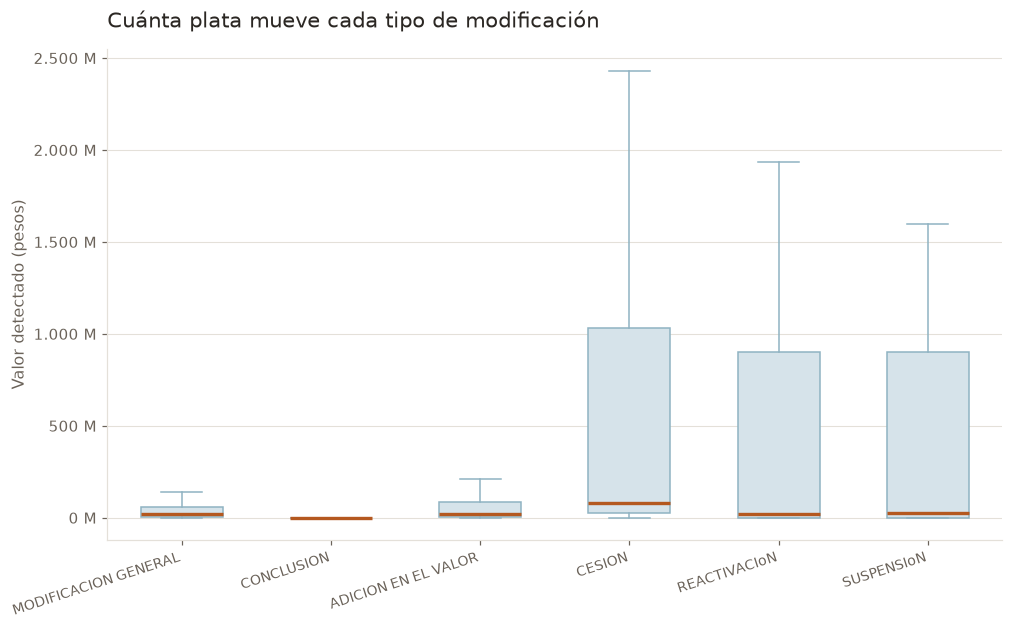

Mediana del valor por tipo:
tipo
CESION                  80258570.0
SUSPENSIoN              25286749.0
ADICION EN EL VALOR     20000000.0
MODIFICACION GENERAL    19359600.0
REACTIVACIoN            18000000.0
CONCLUSION                147010.0


In [26]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Dibuja el diagrama de cajas por tipo de modificación.
# POR QUÉ    : El tipo es una variable de categorías, y para cruzar categorías contra una variable continua la herramienta correcta es la caja. showfliers=False oculta los valores extremos para que las cajas se vean.
# RESUELVE   : Compara cuánta plata mueve cada clase de modificación.
# ────────────────────────────────────────────────────────────────────

top_tipos = df["tipo"].value_counts().head(6).index.tolist()
sub = df[df["tipo"].isin(top_tipos) & df["valor_detectado"].notna()]
datos = [sub.loc[sub["tipo"] == t, "valor_detectado"].values for t in top_tipos]

fig, ax = plt.subplots(figsize=(10.5, 5.8))
ax.boxplot(datos, patch_artist=True, widths=.55, showfliers=False,
           medianprops=dict(color=ACC, lw=2.2),
           boxprops=dict(facecolor="#D6E3EA", edgecolor="#8FB3C2", lw=1),
           whiskerprops=dict(color="#8FB3C2", lw=1),
           capprops=dict(color="#8FB3C2", lw=1))
ax.set_xticks(range(1, len(top_tipos)+1))
ax.set_xticklabels([t[:22] for t in top_tipos], rotation=18, ha="right", fontsize=9)
ax.set_ylabel("Valor detectado (pesos)", fontsize=10.5)
ax.yaxis.set_major_formatter(lambda v, p: f"{v/1e6:,.0f} M".replace(",", "."))
limpiar_ejes(ax)
ax.set_title("Cuánta plata mueve cada tipo de modificación",
             fontsize=13.5, color=INK, pad=14, loc="left")
plt.show()

print("Mediana del valor por tipo:")
print(sub.groupby("tipo")["valor_detectado"].median().sort_values(ascending=False).round(0).to_string())

### 5.5 Complemento: cuántas modificaciones se registran cada mes

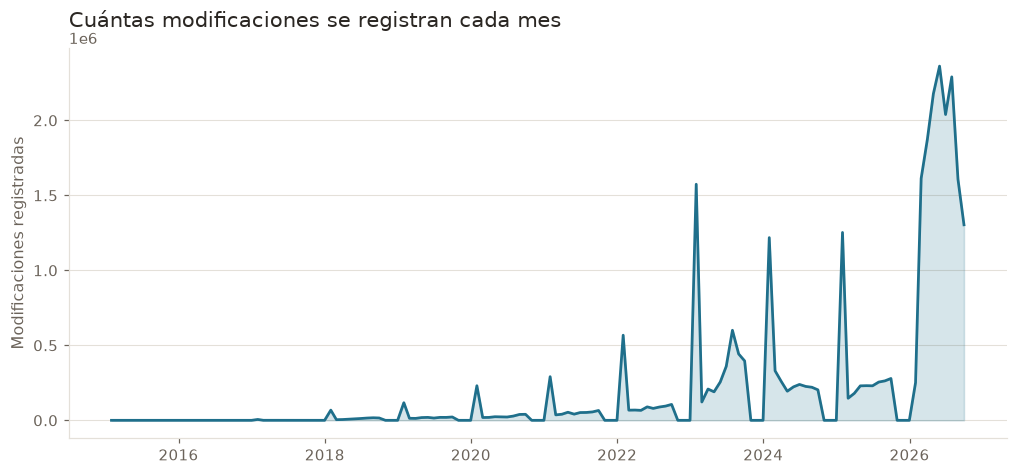

Modificaciones por año:
fecha
2015           8
2016         584
2017        9516
2018      154476
2019      258473
2020      445732
2021      689027
2022     1229147
2023     4149262
2024     3113886
2025     3067849
2026    15515908


In [27]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Dibuja cuántas modificaciones se registran cada mes.
# POR QUÉ    : resample('ME') agrupa por mes calendario y cuenta. Es la forma estándar de convertir una lista de fechas en una serie de tiempo.
# RESUELVE   : Muestra la evolución del fenómeno y detecta saltos o vacíos en el registro.
# ────────────────────────────────────────────────────────────────────

serie = df.dropna(subset=["fecha"]).set_index("fecha").resample("ME").size()

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.fill_between(serie.index, serie.values, color=HUE, alpha=.18)
ax.plot(serie.index, serie.values, color=HUE, lw=1.8)
ax.set_ylabel("Modificaciones registradas", fontsize=10.5)
limpiar_ejes(ax)
ax.set_title("Cuántas modificaciones se registran cada mes",
             fontsize=13.5, color=INK, pad=14, loc="left")
plt.show()

print("Modificaciones por año:")
print(df["fecha"].dt.year.value_counts().sort_index().to_string())

## Punto 6 · Llaves para conectar con otras tablas

In [28]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Evalúa qué columnas sirven como llave.
# POR QUÉ    : Una llave debe ser única y sin vacíos. Aquí solo hay dos candidatas, y de ellas id_contrato es la que conecta con el resto del ecosistema.
# RESUELVE   : Entrega el punto 6 del ejercicio.
# ────────────────────────────────────────────────────────────────────

print("CANDIDATAS A LLAVE\n" + "-" * 60)
for col in ["identificador", "id_contrato"]:
    print(f"{col:16} únicos={df[col].nunique():10,}  vacíos={df[col].isna().sum():8,}"
          .replace(",", "."))

print(f"\nModificaciones por contrato (promedio) : "
      f"{df.groupby('id_contrato').size().mean():.2f}")
print(f"Contrato con más modificaciones        : {df.groupby('id_contrato').size().max()}")

CANDIDATAS A LLAVE
------------------------------------------------------------
identificador    únicos= 8.272.724  vacíos=       0
id_contrato      únicos= 3.907.005  vacíos=       0

Modificaciones por contrato (promedio) : 7.33
Contrato con más modificaciones        : 2078


### Con qué otras tablas se puede unir

| Columna | Qué identifica | Calidad |
|---|---|---|
| `identificador` | La modificación | **Llave primaria.** Debe ser única |
| `id_contrato` | El contrato modificado | **La llave de oro.** Es la que conecta con todo lo demás |

| Para responder… | Se une con | Por la columna |
|---|---|---|
| ¿Cuál era el valor original del contrato? | SECOP II — Contratos Electrónicos (`jbjy-vk9h`) | `id_contrato` ↔ `id_contrato` |
| ¿Qué entidad lo firmó y con qué proveedor? | SECOP II — Contratos Electrónicos (`jbjy-vk9h`) | `id_contrato` ↔ `id_contrato` |
| ¿Cómo fue el proceso que lo originó? | SECOP II — Procesos de Contratación (`p6dx-8zbt`) | vía `proceso_de_compra` de la tabla de contratos |
| ¿El proveedor era un consorcio? | Grupos de Proveedores (`ceth-n4bn`) | vía el NIT del proveedor |

**El análisis potente aparece con el primer cruce.** Al unir esta tabla con la de contratos electrónicos se puede calcular **cuánto creció cada contrato respecto de su valor inicial**, que es la pregunta que de verdad importa. Con esta tabla sola no se puede, porque aquí no está el valor original.

## Cierre · Lo que nos llevamos

**Cinco cosas que no se veían al abrir el archivo:**

1. Una fila no es un contrato: es una modificación hecha a un contrato.
2. La base no tiene ni una columna numérica. Todo el análisis cuantitativo hubo que fabricarlo.
3. La plata está escondida dentro de un texto escrito a mano, y sacarla es una estimación, no un dato oficial.
4. Hay descripciones de plantilla que se repiten miles de veces, lo que vuelve esa columna menos útil de lo que aparenta.
5. Tres de las variables de tiempo se calculan desde la misma fecha, así que sus correlaciones son en parte espurias.

**Tres cosas que se podrían hacer después:**

- Cruzar con la tabla de contratos para medir cuánto crece cada contrato respecto de su valor inicial.
- Medir qué entidades modifican más sus contratos, en proporción a cuántos firman.
- Analizar el texto de las descripciones para clasificar los motivos de la modificación.

**La lección del oficio:** cuando una tabla no trae números, el trabajo no es buscar otra tabla. El trabajo es construir los números con criterio y declarar cómo se construyeron.

---

**Fuente:** [SECOP II - Adiciones (`cb9c-h8sn`) · datos.gov.co](https://www.datos.gov.co/d/cb9c-h8sn) — Agencia Nacional de Contratación Pública, Colombia Compra Eficiente. Licencia Creative Commons Attribution Share-Alike 4.0.

---

# Punto 7 · ¿Esta base entra en el análisis global?

Hasta aquí describimos la base. Ahora la decisión que de verdad importa: **si esta tabla merece un lugar en el proyecto o si es mejor dejarla afuera.**

La respuesta depende de para quién estemos trabajando.

### Los tres actores posibles

| | Quién es | Qué decisión toma |
|---|---|---|
| **A · Contraloría** | Órgano de control fiscal, veeduría, prensa investigativa | Qué procesos audita primero, con recursos limitados |
| **B · Entidad compradora** | La alcaldía, ministerio o empresa estatal que firma el contrato | Cómo planea mejor y cómo supervisa la ejecución |
| **C · Empresa proveedora** | La empresa que quiere ganarse el contrato | A qué proceso se presenta y con qué precio |

### Los cinco criterios

1. **Pertinencia** — ¿responde una pregunta que ese actor realmente se hace?
2. **Unidad de análisis** — ¿lo que hay en las filas coincide con lo que ese actor decide?
3. **Autosuficiencia** — ¿sirve sola, o solo cruzada?
4. **Validabilidad** — ¿ese actor puede comprobar si el resultado le sirvió?
5. **Costo de limpieza** — ¿cuánto trabajo cuesta dejarla usable?

Primero las evidencias.

In [29]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Calcula las evidencias que sustentan la decisión final.
# POR QUÉ    : Se mide la calidad del dato de dinero, lo que la tabla no tiene, qué tan inestables son los contratos, qué tan rápido llegan las modificaciones y la capacidad de cruce.
# RESUELVE   : Convierte la decisión del punto 7 en un argumento con números.
# ────────────────────────────────────────────────────────────────────

print("EVIDENCIAS PARA LA DECISIÓN")
print("=" * 62)

# 1) Calidad del dato de dinero, que es el corazón de esta base
con_valor = df["valor_detectado"].notna().mean()
print(f"\n1. CALIDAD DEL DATO DE DINERO")
print(f"   Filas con monto detectable en el texto : {con_valor*100:5.1f} %")
print(f"   Filas sin ninguna cifra                : {(1-con_valor)*100:5.1f} %")
print(f"   El valor NO viene en una columna propia: se estima del texto libre")

# 2) ¿Qué NO tiene esta tabla?
print(f"\n2. LO QUE ESTA TABLA NO TIENE")
for f in ["entidad que firmó el contrato", "proveedor contratado",
          "valor original del contrato", "objeto del contrato",
          "sector, región o modalidad"]:
    print(f"   · {f}")

# 3) Inestabilidad de los contratos
por_contrato = df.groupby("id_contrato").size()
print(f"\n3. INESTABILIDAD DE LOS CONTRATOS")
print(f"   Contratos distintos                  : {len(por_contrato):,}".replace(",", "."))
print(f"   Con una sola modificación            : {(por_contrato == 1).sum():,}".replace(",", "."))
print(f"   Con dos o más                        : {(por_contrato >= 2).sum():,}".replace(",", "."))
print(f"   Con cinco o más                      : {(por_contrato >= 5).sum():,}".replace(",", "."))
print(f"   Máximo de modificaciones en uno solo : {por_contrato.max()}")

# 4) Velocidad: ¿cuándo llegan las modificaciones?
rapidas = (df["dias_desde_primera"] <= 30).mean()
print(f"\n4. VELOCIDAD DE LA MODIFICACIÓN")
print(f"   Modificaciones dentro de los 30 días de la primera : {rapidas*100:5.1f} %")
print(f"   Mediana de días desde la primera                   : "
      f"{df['dias_desde_primera'].median():.0f}")

# 5) Capacidad de cruce
print(f"\n5. CAPACIDAD DE CRUCE")
print(f"   Filas con id_contrato utilizable : {df['id_contrato'].notna().mean()*100:5.1f} %")
print(f"   Esa columna es la única puerta hacia el resto del ecosistema")

EVIDENCIAS PARA LA DECISIÓN

1. CALIDAD DEL DATO DE DINERO
   Filas con monto detectable en el texto :   6.4 %
   Filas sin ninguna cifra                :  93.6 %
   El valor NO viene en una columna propia: se estima del texto libre

2. LO QUE ESTA TABLA NO TIENE
   · entidad que firmó el contrato
   · proveedor contratado
   · valor original del contrato
   · objeto del contrato
   · sector, región o modalidad

3. INESTABILIDAD DE LOS CONTRATOS
   Contratos distintos                  : 3.907.005
   Con una sola modificación            : 657.258
   Con dos o más                        : 3.249.747
   Con cinco o más                      : 1.667.085
   Máximo de modificaciones en uno solo : 2078

4. VELOCIDAD DE LA MODIFICACIÓN
   Modificaciones dentro de los 30 días de la primera :  59.5 %
   Mediana de días desde la primera                   : 0

5. CAPACIDAD DE CRUCE
   Filas con id_contrato utilizable : 100.0 %
   Esa columna es la única puerta hacia el resto del ecosistema


### Lectura de las evidencias

**La cifra 1 define todo.** Que el valor haya que estimarlo de un texto escrito a mano no es un detalle: es la principal debilidad de esta base y hay que declararla en cualquier uso.

**La cifra 3 es la que justifica traerla.** Los contratos que se modifican muchas veces son un fenómeno real y medible, y ninguna otra tabla lo registra.

**La cifra 5 marca la dependencia.** Sin el cruce por `id_contrato`, esta tabla es una lista de textos sueltos.

---

## 7.1 · Actor A · Contraloría y control fiscal

| Criterio | Evaluación |
|---|---|
| **Pertinencia** | **Muy alta.** El sobrecosto después de firmado es el corazón de la vigilancia fiscal. Un contrato que crece 60 % es exactamente lo que un auditor busca |
| **Unidad de análisis** | **Alta.** El auditor revisa contratos, y aquí cada fila cuelga de un contrato |
| **Autosuficiencia** | **Media.** Sola ya permite detectar contratos con muchas modificaciones o con adiciones muy tempranas |
| **Validabilidad** | **Media.** Abrir el expediente confirma o descarta el hallazgo |
| **Costo de limpieza** | **Medio.** La extracción del valor desde el texto es trabajo real y discutible |

### Lo que le aporta

- **Contratos que se modifican sin parar.** Detectables sin cruzar con nada.
- **Adiciones inmediatas.** Un contrato adicionado a los pocos días de firmado apunta a planeación deficiente o a un valor inicial puesto a propósito por debajo del umbral de una licitación más exigente. Esta es la señal más accionable de toda la base.
- **Crecimiento del gasto.** Con el cruce, permite calcular cuánto creció cada contrato respecto de lo adjudicado.

### Lo que le falta

- **No dice de quién es el contrato.** Sin cruzar no se puede señalar a una entidad ni a un proveedor.
- **El valor es una estimación.** Un hallazgo sostenido sobre una cifra sacada de texto libre se cae en una defensa formal. Sirve para priorizar, no para acusar.

### Veredicto para el actor A

> **Entra, y con peso propio.** Es la única tabla que registra qué pasa con un contrato después de firmado, y esa ventana es donde se produce buena parte del sobrecosto público. Las señales de «modificado muchas veces» y «adicionado muy rápido» se calculan sin depender de nadie, lo cual la hace útil desde el primer día.

---

## 7.2 · Actor B · Entidad pública compradora

| Criterio | Evaluación |
|---|---|
| **Pertinencia** | **Alta.** Es su propio espejo: cuántos de mis contratos tuve que modificar y qué tan rápido |
| **Unidad de análisis** | **Alta.** La entidad supervisa contratos, que es justo lo que hay aquí |
| **Autosuficiencia** | **Baja.** No existe la columna de entidad, así que no puede filtrar lo suyo sin cruzar |
| **Validabilidad** | **Muy alta.** La entidad conoce sus propios expedientes y puede verificar cada caso |
| **Costo de limpieza** | **Medio** |

### Lo que le aporta

- **Un indicador de calidad de planeación.** El porcentaje de contratos que terminan modificados es una métrica dura de desempeño interno, y hoy casi ninguna entidad la calcula.
- **Comparación contra el resto del sector.** Saber si modifica más o menos que entidades parecidas.
- **Alerta temprana de supervisión.** Contratos con varias modificaciones en poco tiempo necesitan más atención.

### Lo que le falta

- **La columna de entidad.** Esta es la barrera práctica: una alcaldía no puede ver sus propios contratos sin pasar antes por la tabla de contratos electrónicos.
- **El valor original**, que es lo que convierte una adición en un porcentaje de crecimiento.

### Veredicto para el actor B

> **Entra, condicionada al cruce.** El indicador de «porcentaje de mis contratos que terminan modificados» es valioso y poco explotado. Pero sin el cruce con la tabla de contratos, la entidad no puede ni siquiera encontrar sus propios registros. El cruce es obligatorio, no opcional.

---

## 7.3 · Actor C · Empresa que quiere ganar el contrato

| Criterio | Evaluación |
|---|---|
| **Pertinencia** | **Media.** La empresa decide a qué presentarse. Esta tabla habla de lo que pasa después de ganar |
| **Unidad de análisis** | **Baja.** Su decisión es sobre procesos abiertos; aquí hay contratos ya firmados y modificados |
| **Autosuficiencia** | **Baja.** Sin la entidad ni el proveedor, no puede construir un perfil de cliente |
| **Validabilidad** | **Media.** Podría contrastar contra su propia experiencia contractual |
| **Costo de limpieza** | **Medio**, alto en relación con lo que obtiene |

### Lo poco que sí le aporta

- **Perfil de cliente público.** Con el cruce, saber qué entidades prorrogan y adicionan con frecuencia. Una entidad que adiciona seguido puede ser buena noticia —contratos que crecen— o mala —planeación errática que desordena la operación.
- **Expectativa realista de duración.** Cuánto suelen extenderse los contratos de cierto tipo, útil para planear capacidad.

### Lo que le falta

- **No le dice a qué presentarse**, que es su decisión central.
- **No tiene el proveedor**, así que no puede ni ver sus propios contratos sin dos cruces.
- La información llega **después de la decisión que le importa**.

### Veredicto para el actor C

> **No entra en el núcleo. Entra como enriquecimiento de segundo orden.** Si el proyecto se enfoca en la empresa proveedora, esta base se deja para una fase posterior: cuando ya exista el motor de priorización de oportunidades y se le quiera agregar una variable de calidad del cliente público.

---

## 7.4 · Decisión

| | **A · Contraloría** | **B · Entidad compradora** | **C · Empresa proveedora** |
|---|---|---|---|
| Pertinencia | Muy alta | Alta | Media |
| Unidad de análisis | Alta | Alta | Baja |
| Autosuficiencia | Media | Baja | Baja |
| Validabilidad | Media | Muy alta | Media |
| Costo de limpieza | Medio | Medio | Medio |
| **Decisión** | **Entra con peso propio** | **Entra, condicionada al cruce** | **Fase posterior** |

### Recomendación

**Si el proyecto se enfoca en el control fiscal, esta base es prioritaria.** Es la única que registra la vida del contrato después de la firma, y ahí es donde se produce el sobrecosto. Además da señales útiles sin depender de ningún cruce.

**Si el proyecto se enfoca en la entidad compradora, entra pero con una condición dura:** hay que resolver primero el cruce con la tabla de contratos, porque sin eso la entidad no encuentra sus propios registros.

**Si el proyecto se enfoca en la empresa proveedora, se deja para después.** El costo de limpieza es alto y lo que aporta llega tarde respecto de la decisión que a la empresa le importa.

### La advertencia metodológica que hay que llevar a la sustentación

**El valor de la adición no es un dato de la fuente: es una estimación construida por nosotros a partir de texto escrito a mano.** Eso condiciona todo uso posterior:

- Sirve para **priorizar** qué revisar. No sirve para **afirmar** cuánto creció un contrato.
- Los indicadores que no dependen del valor —número de modificaciones, días hasta la primera adición— son **más robustos** y conviene apoyarse en ellos.
- Si el proyecto necesita el valor exacto de las adiciones, la ruta correcta es el cruce con la tabla de contratos electrónicos, donde sí hay columnas de valor.

### El plan mínimo de integración, en orden

1. Cruzar por `id_contrato` con `jbjy-vk9h` para traer entidad, proveedor y valor original.
2. Calcular el crecimiento porcentual de cada contrato respecto de lo adjudicado.
3. Construir el indicador de «tasa de modificación» por entidad, que es el producto final y el que justifica haber traído esta base al proyecto.